# Port Value Learning

How to fit a reinforcement learning model to a session of the rat's port choices and get each port's value at the start of every trial. 


For each trial in a session, you need:

- a list of ports the rat ran to, specified as `"A"`/`"B"`/`"C"` or `1`/`2`/`3` e.g. `["B", "A", "C", "A", ...]`
- a list of reward/omission at those ports, specified as `1` (reward) or `0` (omission) e.g. `[0, 1, 1, 1, ...]`

Both lists need every trial of the session, in order, with none missing (each trip starts at the port the rat ran to on the trial before).


### Load an example session

We have 2 example sessions (a probability change session and a barrier change session), each a csv with one row per trial. `load_session` (in [tutorial_utils.py](tutorial_utils.py)) loads one, and we only need 2 things from it: `ports` and `rewards`. Change `SESSION_FILE` to try the other session.

To use your own data, you just need these 2 lists (one entry per trial, in order).

In [1]:
import sys
sys.path.append("..")  # Use sys to add the parent directory (where src/hexmaze lives) to the path

import matplotlib.pyplot as plt
import pandas as pd
from src.hexmaze.rl.port_learning import RescorlaWagner, port_values_per_trial
from tutorial_utils import draw_blocks, load_session

# Example sessions
EXAMPLE_SESSIONS = [
    "example_data/IM-1871_20250802_ep0_98178d7d.csv",  # probability change (rat IM-1871)
    "example_data/Toby20250327_ep7_b94510ec.csv",  # barrier change (rat Toby)
]

SESSION_FILE = EXAMPLE_SESSIONS[0] # Change the number to try the other session
session = load_session(SESSION_FILE)

# The 2 things we need: the port the rat ran to on each trial, and whether it got rewarded
ports = session["ports"]
rewards = session["rewards"]
print(f"{SESSION_FILE}: {len(ports)} trials ({session['session_type']} change session)")
display(pd.DataFrame({"port": ports, "reward": rewards}).head())

example_data/IM-1871_20250802_ep0_98178d7d.csv: 178 trials (probability change session)


,port,reward
0,B,0.0
1,A,1.0
2,C,1.0
3,A,1.0
4,B,0.0


### Fit a model and get port values per trial

Here we use `RescorlaWagner` (Q-learning): each port has a value (Q), and after the rat runs to a port, that port's value moves toward the outcome by a learning rate alpha.

`fit_choices` fits the model's parameters (alpha, decay and beta) to the rat's choices. Then `port_values_per_trial` runs the fitted model on the session and gives a table with one row per trial:
- **start port**, **port**, **reward**: the port the rat left, the port it ran to, and whether it got rewarded
- **A**, **B**, **C**: each port's value at the start of the trial (before learning from that trial)
- **p(A)**, **p(B)**, **p(C)**: the model's probability of choosing each port (NaN for the port the rat just left, since it wasn't an option)


#### NOTE: fit_choices vs fit_rewards
We use `fit_choices` here because we want the parameters that maximize p(choose port) for each of the rat's port choices. This asks "Given the model's port values, how likely was the rat to pick the port it picked (out of the 2 ports it didn't just visit)?"
- Sometimes this gives bad fits (e.g. a huge beta and port values stuck near 0.5) because the rat's choices are guided by distance etc and not just port value! See section 7 of [Port Value Models Extended](42_Port_Value_Models_Extended.ipynb).

You can also use `fit_rewards`, which fits the model to maximize the likelihood of the observed rewards instead ("Given the model's port values, how likely was the rat to get rewarded (or not) on each trial?"). Fitting to observed rewards ends up giving values that track the true p(reward) more closely.

In [2]:
# Fit alpha, decay and beta (inverse temperature) to the rat's port choices
fit = RescorlaWagner.fit_choices(ports, rewards)
print(f"alpha = {fit.alpha:.3f}, decay = {fit.decay:.3f}, beta (inverse temp) = {fit.beta:.3f}")

# Get each port's value at the start of every trial
port_values = port_values_per_trial(fit, ports, rewards)
display(port_values)

alpha = 0.067, decay = 0.000, beta (inverse temp) = 6.537


,start port,port,reward,A,B,C,p(A),p(B),p(C)
trial,,,,,,,,,
1,None,B,0.0,0.500000,0.500000,0.500000,0.333333,0.333333,0.333333
2,B,A,1.0,0.500000,0.466616,0.500000,0.500000,NaN,0.500000
3,A,C,1.0,0.533384,0.466616,0.500000,NaN,0.445657,0.554343
4,C,A,1.0,0.533384,0.466616,0.533384,0.607417,0.392583,NaN
5,A,B,0.0,0.564538,0.466616,0.533384,NaN,0.392583,0.607417
...,...,...,...,...,...,...,...,...,...
174,A,B,1.0,0.574135,0.313163,0.408710,NaN,0.348735,0.651265
175,B,A,1.0,0.574135,0.359021,0.408710,0.746762,NaN,0.253238
176,A,B,0.0,0.602569,0.359021,0.408710,NaN,0.419501,0.580499


### Plot port values

Each port's value at the start of every trial, with a dot on the trials the rat ran there (filled if rewarded). Red lines mark block changes.

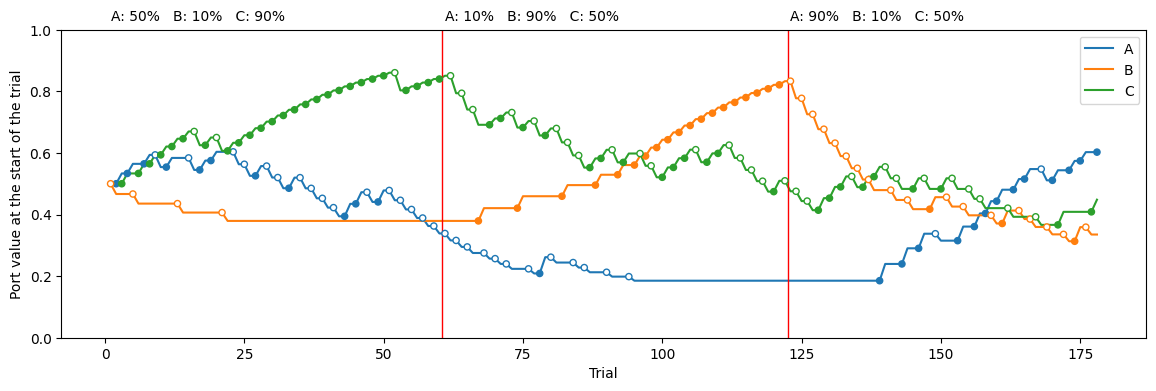

In [3]:
PORT_COLORS = {"A": "tab:blue", "B": "tab:orange", "C": "tab:green"}

fig, ax = plt.subplots(figsize=(14, 4))
# Loop through ports to plot each port's values (with a dot on each visit)
for name, color in PORT_COLORS.items():
    ax.plot(port_values.index, port_values[name], color=color, label=name)
    visits = port_values[port_values["port"] == name]
    ax.scatter(visits.index, visits[name], color=color, s=20, zorder=3,
               facecolors=[color if reward else "white" for reward in visits["reward"]])
draw_blocks(ax, session)

ax.set_xlabel("Trial")
ax.set_ylabel("Port value at the start of the trial")
ax.set_ylim(0, 1)
ax.legend()
plt.show()

### Other models

If we want to fit a different model than Q learning, swap `RescorlaWagner` for another model and the rest stays the same. For example, here are the Bayesian and Hidden State models (below).

The available models are `RescorlaWagner`, `BayesianPortLearner`, `HiddenStatePortLearner` and `BayesianHiddenStatePortLearner` (see the port learning [README](../src/hexmaze/rl/port_learning/README.md)). Note `BayesianHiddenStatePortLearner` is weird and experimental still. 

See [Port Value Models](41_Port_Value_Models.ipynb) for each model's equations and comparing models, and [Port Value Models Extended](42_Port_Value_Models_Extended.ipynb) for what each parameter does, uncertainty, and more.

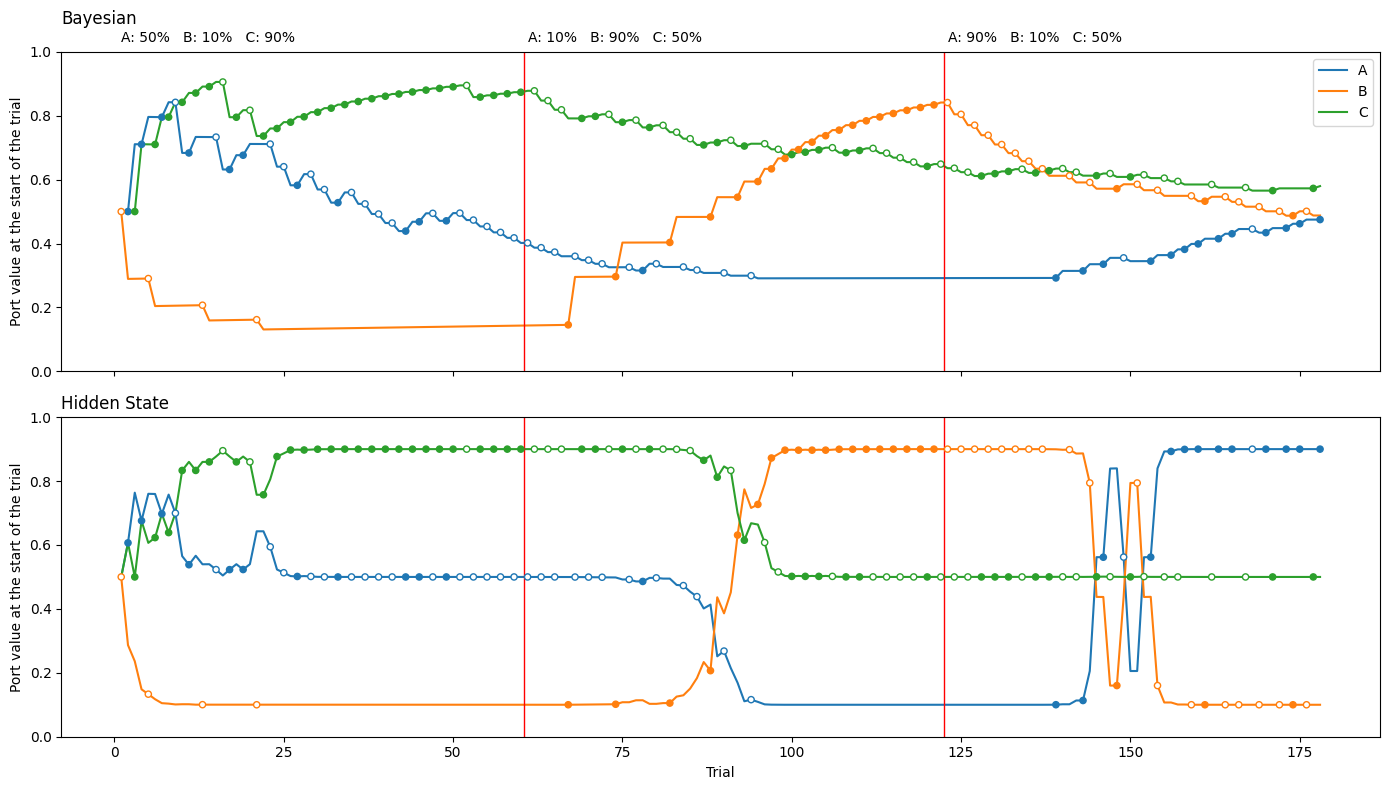

In [4]:
from src.hexmaze.rl.port_learning import BayesianPortLearner, HiddenStatePortLearner

# Fit the Bayesian and Hidden State models to the rat's port choices
bayes_fit = BayesianPortLearner.fit_choices(ports, rewards)
hidden_state_fit = HiddenStatePortLearner.fit_choices(ports, rewards)

# Get each port's value at the start of every trial for both models
bayes_values = port_values_per_trial(bayes_fit, ports, rewards)
hidden_state_values = port_values_per_trial(hidden_state_fit, ports, rewards)

# Plot port values for both models (same as above, Bayesian on top and Hidden State on the bottom)
fig, (bayes_ax, hidden_state_ax) = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
# Loop through ports to plot each port's values for both models
for name, color in PORT_COLORS.items():
    bayes_ax.plot(bayes_values.index, bayes_values[name], color=color, label=name)
    visits = bayes_values[bayes_values["port"] == name]
    bayes_ax.scatter(visits.index, visits[name], color=color, s=20, zorder=3,
                     facecolors=[color if reward else "white" for reward in visits["reward"]])

    hidden_state_ax.plot(hidden_state_values.index, hidden_state_values[name], color=color, label=name)
    visits = hidden_state_values[hidden_state_values["port"] == name]
    hidden_state_ax.scatter(visits.index, visits[name], color=color, s=20, zorder=3,
                            facecolors=[color if reward else "white" for reward in visits["reward"]])

draw_blocks(bayes_ax, session)
draw_blocks(hidden_state_ax, session, show_probabilities=False)
bayes_ax.set_title("Bayesian", loc="left", pad=20)
hidden_state_ax.set_title("Hidden State", loc="left")
bayes_ax.set_ylabel("Port value at the start of the trial")
hidden_state_ax.set_ylabel("Port value at the start of the trial")
bayes_ax.set_ylim(0, 1)
hidden_state_ax.set_ylim(0, 1)
bayes_ax.legend()
hidden_state_ax.set_xlabel("Trial")
plt.tight_layout()
plt.show()
